In [1]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = next(
        (parent for parent in [ROOT, *ROOT.parents] if (parent / "src").exists()),
        ROOT,
    )

sys.path.insert(0, str(ROOT))

# Phase 1 — Recomputed results summary

Notebook này load lại checkpoint và đánh giá trực tiếp trên test set đã phục hồi:

- **Task A:** 4 family, 5 backbone × 3 seed, `data/task-A`.
- **Final-B:** 17 species sau khi loại 3 lớp thiếu dữ liệu, 5 backbone × 3 seed cho main và 3 nhóm ablation seed 42, `data/task-B-group-split`.

Kết quả được tính lại từ prediction hiện tại, không phụ thuộc bảng report hoặc JSON tổng hợp cũ.

In [2]:
if Path('/content').exists():
    !pip install -q -r {ROOT}/requirements.txt

In [3]:
import json
import platform
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from torch.utils.data import DataLoader

from src.data import ConiferDataset, FlatConiferDataset
from src.data.transforms import get_val_transforms
from src.models import create_model

TASK_A_DATA = ROOT / "data" / "task-A"
TASK_B_DATA = ROOT / "data" / "task-B-group-split"
TASK_A_EXPERIMENTS = ROOT / "data" / "experiments" / "Task-A"
TASK_B_EXPERIMENTS = ROOT / "data" / "experiments" / "Task-B"
OUTPUT_DIR = ROOT / "data" / "experiments" / "phase_1" / "summary"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BACKBONES = [
    "resnet50",
    "efficientnet_b3",
    "mobilenetv3_large",
    "convnext_tiny",
    "swin_tiny",
]
SEEDS = [42, 123, 456]
BATCH_SIZE = 64
NUM_WORKERS = 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"ROOT: {ROOT}")
print(f"Device: {DEVICE}")
print(f"Output: {OUTPUT_DIR}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench
Device: cuda
Output: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary


In [4]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}


def image_count(path):
    return sum(
        1 for item in path.rglob("*")
        if item.is_file() and item.suffix.lower() in IMAGE_EXTENSIONS
    )


task_a_expected = {"train": 7264, "val": 955, "test": 981}
task_b_expected = {"train": 3365, "val": 903, "test": 532}

for split, expected in task_a_expected.items():
    actual = image_count(TASK_A_DATA / split)
    assert actual == expected, f"Task A {split}: expected {expected}, got {actual}"

excluded_classes = {
    "Calocedrus sp",
    "Cupressus funebris (Cupressus pendula)",
    "Pinus sp",
}
for split, expected in task_b_expected.items():
    split_dir = TASK_B_DATA / split
    classes = sorted(path.name for path in split_dir.iterdir() if path.is_dir())
    actual = image_count(split_dir)
    assert len(classes) == 17, f"Final-B {split}: expected 17 classes, got {len(classes)}"
    assert excluded_classes.isdisjoint(classes), f"Excluded class remains in {split}"
    assert actual == expected, f"Final-B {split}: expected {expected}, got {actual}"

print("Dataset validation passed")
print("Task A:", task_a_expected)
print("Final-B:", task_b_expected)

Dataset validation passed
Task A: {'train': 7264, 'val': 955, 'test': 981}
Final-B: {'train': 3365, 'val': 903, 'test': 532}


In [5]:
transform = get_val_transforms(img_size=224)

task_a_dataset = ConiferDataset(
    TASK_A_DATA,
    split="test",
    transform=transform,
    task="taskA",
)
task_a_loader = DataLoader(
    task_a_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=NUM_WORKERS > 0,
)

task_b_classes = sorted(
    path.name for path in (TASK_B_DATA / "train").iterdir() if path.is_dir()
)
task_b_dataset = FlatConiferDataset(
    TASK_B_DATA,
    split="test",
    transform=transform,
    task="taskB",
    classes=task_b_classes,
)
task_b_loader = DataLoader(
    task_b_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Task A test: {len(task_a_dataset)} images, {task_a_dataset.classes}")
print(f"Final-B test: {len(task_b_dataset)} images, {len(task_b_classes)} classes")

Task A test: 981 images, ['Cupressaceae', 'Pinaceae', 'Podocarpaceae', 'Taxaceae']
Final-B test: 532 images, 17 classes


In [6]:
def load_checkpoint(path):
    try:
        payload = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        payload = torch.load(path, map_location="cpu")
    state_dict = payload.get("model_state_dict", payload)
    return payload, state_dict


def find_task_a_checkpoint(seed, backbone):
    seed_dir = TASK_A_EXPERIMENTS / f"seed{seed}"
    patterns = {
        "resnet50": "resnet50*/resnet50*.pth",
        "efficientnet_b3": "efficientnet_b3/efficientnet_b3*.pth",
        "mobilenetv3_large": "mobilenetv3_large*/mobilenetv3_large*.pth",
        "convnext_tiny": "convnext_tiny/convnext_tiny*.pth",
        "swin_tiny": "swin_tiny/swin_tiny*.pth",
    }
    candidates = sorted(seed_dir.glob(patterns[backbone]))
    if len(candidates) != 1:
        raise RuntimeError(
            f"Expected one Task A checkpoint for seed={seed}, backbone={backbone}; "
            f"found {candidates}"
        )
    return candidates[0]


def discover_task_b_checkpoints():
    records = []
    for path in sorted(TASK_B_EXPERIMENTS.rglob("*_best.pth")):
        relative = path.relative_to(TASK_B_EXPERIMENTS)
        parts = relative.parts
        if parts[0] == "main":
            experiment = "main"
            seed = int(parts[1].split("_")[-1])
            backbone = parts[2]
        else:
            experiment = parts[0]
            seed = 42
            backbone = parts[1]
        records.append((experiment, seed, backbone, path))
    return records


@torch.inference_mode()
def evaluate_checkpoint(task, experiment, seed, backbone, path, loader, class_names):
    payload, state_dict = load_checkpoint(path)
    model = create_model(backbone, num_classes=len(class_names), pretrained=False)
    model.load_state_dict(state_dict, strict=True)
    model = model.to(DEVICE).eval()

    predictions = []
    labels = []
    for images, targets in loader:
        outputs = model(images.to(DEVICE, non_blocking=True))
        predictions.extend(outputs.argmax(dim=1).cpu().tolist())
        labels.extend(targets.tolist())

    row = {
        "task": task,
        "experiment": experiment,
        "seed": seed,
        "backbone": backbone,
        "num_classes": len(class_names),
        "test_images": len(labels),
        "checkpoint": str(path.relative_to(ROOT)),
        "best_val_acc": float(payload.get("best_val_acc", np.nan)),
        "best_epoch": int(payload.get("best_epoch", payload.get("epoch", -1))) + 1,
        "test_accuracy": float(accuracy_score(labels, predictions)),
        "test_precision_macro": float(
            precision_score(labels, predictions, average="macro", zero_division=0)
        ),
        "test_recall_macro": float(
            recall_score(labels, predictions, average="macro", zero_division=0)
        ),
        "test_f1_macro": float(
            f1_score(labels, predictions, average="macro", zero_division=0)
        ),
        "test_f1_per_class": json.dumps(
            {
                name: float(score)
                for name, score in zip(
                    class_names,
                    f1_score(labels, predictions, average=None, zero_division=0),
                )
            },
            ensure_ascii=False,
        ),
    }

    del model, payload, state_dict
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row

In [7]:
task_a_rows = []
for seed in SEEDS:
    for backbone in BACKBONES:
        checkpoint = find_task_a_checkpoint(seed, backbone)
        row = evaluate_checkpoint(
            task="Task A",
            experiment="main",
            seed=seed,
            backbone=backbone,
            path=checkpoint,
            loader=task_a_loader,
            class_names=task_a_dataset.classes,
        )
        task_a_rows.append(row)
        print(
            f"Task A | {backbone:<20s} | seed={seed:<3d} | "
            f"Acc={row['test_accuracy']*100:6.2f}% | F1={row['test_f1_macro']*100:6.2f}%"
        )

task_a_df = pd.DataFrame(task_a_rows)
task_a_df

Task A | resnet50             | seed=42  | Acc= 98.88% | F1= 97.98%


Task A | efficientnet_b3      | seed=42  | Acc= 98.78% | F1= 97.68%


Task A | mobilenetv3_large    | seed=42  | Acc= 99.59% | F1= 99.04%


Task A | convnext_tiny        | seed=42  | Acc=100.00% | F1=100.00%


Task A | swin_tiny            | seed=42  | Acc=100.00% | F1=100.00%


Task A | resnet50             | seed=123 | Acc= 98.47% | F1= 97.28%


... (6 outputs left out)

Task A | mobilenetv3_large    | seed=456 | Acc= 99.59% | F1= 99.28%


Task A | convnext_tiny        | seed=456 | Acc= 99.69% | F1= 99.35%


Task A | swin_tiny            | seed=456 | Acc=100.00% | F1=100.00%


,task,experiment,seed,backbone,num_classes,test_images,checkpoint,best_val_acc,best_epoch,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_per_class
0,Task A,main,42,resnet50,4,981,data/experiments/Task-A/seed42/resnet50_balanc...,99.162304,48,0.988787,0.967766,0.993709,0.979812,"{""Cupressaceae"": 0.9914040114613181, ""Pinaceae..."
1,Task A,main,42,efficientnet_b3,4,981,data/experiments/Task-A/seed42/efficientnet_b3...,99.895288,18,0.987768,0.966323,0.988179,0.976773,"{""Cupressaceae"": 0.9895337773549001, ""Pinaceae..."
2,Task A,main,42,mobilenetv3_large,4,981,data/experiments/Task-A/seed42/mobilenetv3_lar...,99.581152,23,0.995923,0.988072,0.992805,0.990411,"{""Cupressaceae"": 0.9971401334604385, ""Pinaceae..."
3,Task A,main,42,convnext_tiny,4,981,data/experiments/Task-A/seed42/convnext_tiny/c...,100.000000,10,1.000000,1.000000,1.000000,1.000000,"{""Cupressaceae"": 1.0, ""Pinaceae"": 1.0, ""Podoca..."
4,Task A,main,42,swin_tiny,4,981,data/experiments/Task-A/seed42/swin_tiny/swin_...,100.000000,5,1.000000,1.000000,1.000000,1.000000,"{""Cupressaceae"": 1.0, ""Pinaceae"": 1.0, ""Podoca..."
5,Task A,main,123,resnet50,4,981,data/experiments/Task-A/seed123/resnet50/resne...,98.952880,38,0.984709,0.956825,0.990962,0.972837,"{""Cupressaceae"": 0.9885714285714285, ""Pinaceae..."
6,Task A,main,123,efficientnet_b3,4,981,data/experiments/Task-A/seed123/efficientnet_b...,99.895288,14,0.983690,0.951175,0.980352,0.965062,"{""Cupressaceae"": 0.9895536562203229, ""Pinaceae..."
7,Task A,main,123,mobilenetv3_large,4,981,data/experiments/Task-A/seed123/mobilenetv3_la...,99.685864,23,0.996942,0.998153,0.998361,0.998256,"{""Cupressaceae"": 0.9971401334604385, ""Pinaceae..."
8,Task A,main,123,convnext_tiny,4,981,data/experiments/Task-A/seed123/convnext_tiny/...,100.000000,7,1.000000,1.000000,1.000000,1.000000,"{""Cupressaceae"": 1.0, ""Pinaceae"": 1.0, ""Podoca..."
9,Task A,main,123,swin_tiny,4,981,data/experiments/Task-A/seed123/swin_tiny/swin...,100.000000,4,1.000000,1.000000,1.000000,1.000000,"{""Cupressaceae"": 1.0, ""Pinaceae"": 1.0, ""Podoca..."


In [8]:
task_b_records = discover_task_b_checkpoints()
assert len(task_b_records) == 30, f"Expected 30 Final-B best checkpoints, got {len(task_b_records)}"

task_b_rows = []
for experiment, seed, backbone, checkpoint in task_b_records:
    row = evaluate_checkpoint(
        task="Final-B",
        experiment=experiment,
        seed=seed,
        backbone=backbone,
        path=checkpoint,
        loader=task_b_loader,
        class_names=task_b_classes,
    )
    task_b_rows.append(row)
    print(
        f"Final-B | {experiment:<26s} | {backbone:<20s} | seed={seed:<3d} | "
        f"Acc={row['test_accuracy']*100:6.2f}% | F1={row['test_f1_macro']*100:6.2f}%"
    )

task_b_df = pd.DataFrame(task_b_rows)
task_b_df

Final-B | main                       | convnext_tiny        | seed=123 | Acc= 99.44% | F1= 99.48%


Final-B | main                       | efficientnet_b3      | seed=123 | Acc= 97.37% | F1= 97.45%


Final-B | main                       | mobilenetv3_large    | seed=123 | Acc= 98.68% | F1= 98.73%


Final-B | main                       | resnet50             | seed=123 | Acc= 92.29% | F1= 92.49%


Final-B | main                       | swin_tiny            | seed=123 | Acc= 99.81% | F1= 99.83%


Final-B | main                       | convnext_tiny        | seed=42  | Acc= 99.62% | F1= 99.61%


... (21 outputs left out)

Final-B | taskB_label_smoothing_0.2  | mobilenetv3_large    | seed=42  | Acc= 98.68% | F1= 98.73%


Final-B | taskB_label_smoothing_0.2  | resnet50             | seed=42  | Acc= 93.98% | F1= 94.09%


Final-B | taskB_label_smoothing_0.2  | swin_tiny            | seed=42  | Acc= 99.62% | F1= 99.66%


,task,experiment,seed,backbone,num_classes,test_images,checkpoint,best_val_acc,best_epoch,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_per_class
0,Final-B,main,123,convnext_tiny,17,532,data/experiments/Task-B/main/seed_123/convnext...,99.889258,16,0.994361,0.994810,0.995098,0.994830,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
1,Final-B,main,123,efficientnet_b3,17,532,data/experiments/Task-B/main/seed_123/efficien...,96.566999,38,0.973684,0.977088,0.973950,0.974476,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
2,Final-B,main,123,mobilenetv3_large,17,532,data/experiments/Task-B/main/seed_123/mobilene...,95.570321,47,0.986842,0.988253,0.987101,0.987280,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
3,Final-B,main,123,resnet50,17,532,data/experiments/Task-B/main/seed_123/resnet50...,90.365449,49,0.922932,0.934915,0.925112,0.924904,"{""Araucaria araucana"": 0.9655172413793104, ""Ca..."
4,Final-B,main,123,swin_tiny,17,532,data/experiments/Task-B/main/seed_123/swin_tin...,99.778516,10,0.998120,0.998217,0.998366,0.998267,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
5,Final-B,main,42,convnext_tiny,17,532,data/experiments/Task-B/main/seed_42/convnext_...,99.889258,20,0.996241,0.996379,0.995915,0.996081,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
6,Final-B,main,42,efficientnet_b3,17,532,data/experiments/Task-B/main/seed_42/efficient...,95.791805,32,0.969925,0.971164,0.970001,0.969505,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
7,Final-B,main,42,mobilenetv3_large,17,532,data/experiments/Task-B/main/seed_42/mobilenet...,95.348837,43,0.984962,0.986688,0.985263,0.985533,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
8,Final-B,main,42,resnet50,17,532,data/experiments/Task-B/main/seed_42/resnet50/...,90.586932,50,0.947368,0.953093,0.948177,0.948664,"{""Araucaria araucana"": 1.0, ""Callitris columel..."
9,Final-B,main,42,swin_tiny,17,532,data/experiments/Task-B/main/seed_42/swin_tiny...,99.667774,7,0.990602,0.992051,0.991830,0.991348,"{""Araucaria araucana"": 1.0, ""Callitris columel..."


In [9]:
all_runs_df = pd.concat([task_a_df, task_b_df], ignore_index=True)
metric_columns = [
    "test_accuracy",
    "test_precision_macro",
    "test_recall_macro",
    "test_f1_macro",
]

main_df = all_runs_df[all_runs_df["experiment"] == "main"].copy()
summary_rows = []
for (task, backbone), group in main_df.groupby(["task", "backbone"], sort=False):
    row = {
        "task": task,
        "backbone": backbone,
        "runs": len(group),
    }
    for metric in metric_columns:
        values = group[metric].astype(float)
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=0)
    summary_rows.append(row)

main_summary_df = pd.DataFrame(summary_rows)
display_columns = [
    "task",
    "backbone",
    "runs",
    "test_accuracy_mean",
    "test_accuracy_std",
    "test_f1_macro_mean",
    "test_f1_macro_std",
]
main_summary_df[display_columns].assign(
    test_accuracy_mean=lambda frame: frame["test_accuracy_mean"] * 100,
    test_accuracy_std=lambda frame: frame["test_accuracy_std"] * 100,
    test_f1_macro_mean=lambda frame: frame["test_f1_macro_mean"] * 100,
    test_f1_macro_std=lambda frame: frame["test_f1_macro_std"] * 100,
).round(3)

,task,backbone,runs,test_accuracy_mean,test_accuracy_std,test_f1_macro_mean,test_f1_macro_std
0,Task A,resnet50,3,98.573,0.220,97.442,0.392
1,Task A,efficientnet_b3,3,98.233,0.509,96.608,0.834
2,Task A,mobilenetv3_large,3,99.626,0.048,99.383,0.328
3,Task A,convnext_tiny,3,99.898,0.144,99.784,0.306
4,Task A,swin_tiny,3,100.000,0.000,100.000,0.000
5,Final-B,convnext_tiny,3,99.499,0.089,99.524,0.059
6,Final-B,efficientnet_b3,3,97.118,0.177,97.138,0.221
7,Final-B,mobilenetv3_large,3,98.371,0.319,98.407,0.339
8,Final-B,resnet50,3,93.672,1.022,93.844,0.998
9,Final-B,swin_tiny,3,99.436,0.307,99.481,0.282


In [10]:
task_b_ablation_df = task_b_df[task_b_df["experiment"] != "main"].copy()
task_b_seed42_main = task_b_df[
    (task_b_df["experiment"] == "main") & (task_b_df["seed"] == 42)
][["backbone", "test_accuracy", "test_f1_macro"]].rename(
    columns={
        "test_accuracy": "main_seed42_accuracy",
        "test_f1_macro": "main_seed42_f1",
    }
)
task_b_ablation_df = task_b_ablation_df.merge(task_b_seed42_main, on="backbone")
task_b_ablation_df["accuracy_delta_vs_main"] = (
    task_b_ablation_df["test_accuracy"] - task_b_ablation_df["main_seed42_accuracy"]
)
task_b_ablation_df["f1_delta_vs_main"] = (
    task_b_ablation_df["test_f1_macro"] - task_b_ablation_df["main_seed42_f1"]
)

task_b_ablation_df[[
    "experiment",
    "backbone",
    "test_accuracy",
    "test_f1_macro",
    "accuracy_delta_vs_main",
    "f1_delta_vs_main",
]].assign(
    test_accuracy=lambda frame: frame["test_accuracy"] * 100,
    test_f1_macro=lambda frame: frame["test_f1_macro"] * 100,
    accuracy_delta_vs_main=lambda frame: frame["accuracy_delta_vs_main"] * 100,
    f1_delta_vs_main=lambda frame: frame["f1_delta_vs_main"] * 100,
).round(3)

,experiment,backbone,test_accuracy,test_f1_macro,accuracy_delta_vs_main,f1_delta_vs_main
0,taskB_90rotation,convnext_tiny,100.000,100.000,0.376,0.392
1,taskB_90rotation,efficientnet_b3,98.684,98.721,1.692,1.771
2,taskB_90rotation,mobilenetv3_large,98.684,98.691,0.188,0.137
3,taskB_90rotation,resnet50,95.489,95.525,0.752,0.659
4,taskB_90rotation,swin_tiny,99.812,99.794,0.752,0.659
5,taskB_label_smoothing_0.0,convnext_tiny,99.812,99.827,0.188,0.219
6,taskB_label_smoothing_0.0,efficientnet_b3,96.429,96.446,-0.564,-0.504
7,taskB_label_smoothing_0.0,mobilenetv3_large,98.120,98.169,-0.376,-0.385
8,taskB_label_smoothing_0.0,resnet50,93.797,93.951,-0.940,-0.916
9,taskB_label_smoothing_0.0,swin_tiny,99.436,99.481,0.376,0.346


In [11]:
metadata = {
    "recomputed_at_utc": datetime.now(timezone.utc).isoformat(),
    "device_type": DEVICE.type,
    "device_name": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else platform.processor() or platform.machine(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "task_a": {
        "classes": task_a_dataset.classes,
        "train_images": 7264,
        "val_images": 955,
        "test_images": len(task_a_dataset),
        "checkpoints": len(task_a_df),
    },
    "final_b": {
        "classes": task_b_classes,
        "train_images": 3365,
        "val_images": 903,
        "test_images": len(task_b_dataset),
        "checkpoints": len(task_b_df),
        "excluded_classes": sorted(excluded_classes),
    },
}

all_runs_path = OUTPUT_DIR / "phase1_all_runs_recomputed.csv"
main_summary_path = OUTPUT_DIR / "phase1_main_summary_recomputed.csv"
ablation_path = OUTPUT_DIR / "phase1_task_b_ablation_recomputed.csv"
json_path = OUTPUT_DIR / "phase1_all_runs_recomputed.json"
metadata_path = OUTPUT_DIR / "summary_metadata.json"

all_runs_df.to_csv(all_runs_path, index=False)
main_summary_df.to_csv(main_summary_path, index=False)
task_b_ablation_df.to_csv(ablation_path, index=False)
json_path.write_text(
    json.dumps(all_runs_df.to_dict(orient="records"), indent=2, ensure_ascii=False),
    encoding="utf-8",
)
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Saved: {all_runs_path}")
print(f"Saved: {main_summary_path}")
print(f"Saved: {ablation_path}")
print(f"Saved: {json_path}")
print(f"Saved: {metadata_path}")

Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/phase1_all_runs_recomputed.csv
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/phase1_main_summary_recomputed.csv
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/phase1_task_b_ablation_recomputed.csv
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/phase1_all_runs_recomputed.json
Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/summary_metadata.json


Saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/phase_1/summary/phase1_main_accuracy_recomputed.png


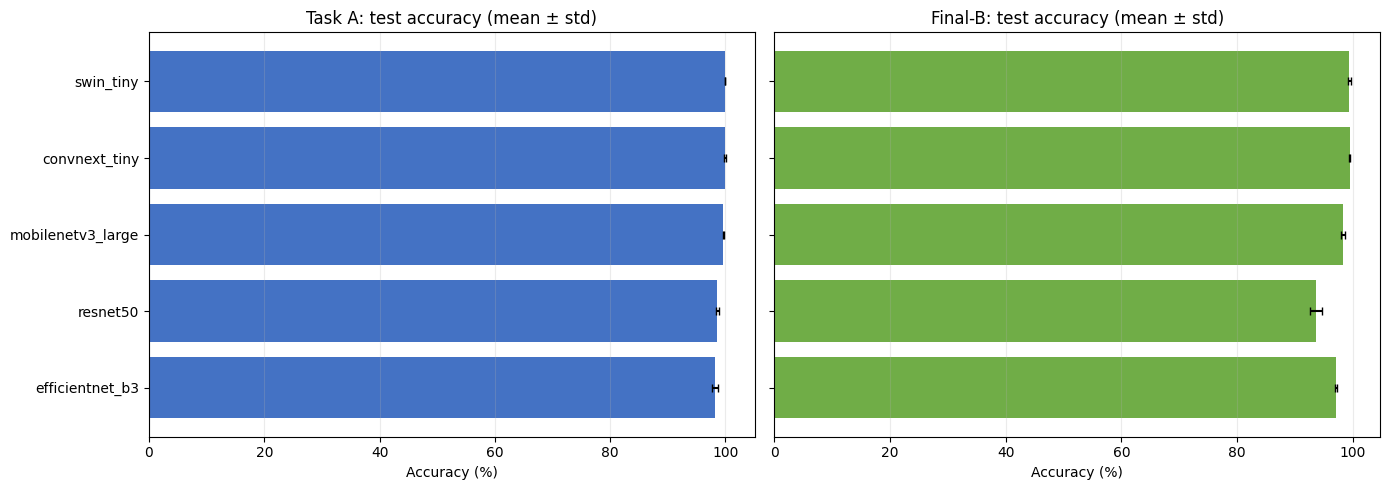

In [12]:
plot_df = main_summary_df.copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for axis, task in zip(axes, ["Task A", "Final-B"]):
    subset = plot_df[plot_df["task"] == task].sort_values("test_accuracy_mean")
    axis.barh(
        subset["backbone"],
        subset["test_accuracy_mean"] * 100,
        xerr=subset["test_accuracy_std"] * 100,
        color="#4472C4" if task == "Task A" else "#70AD47",
        capsize=3,
    )
    axis.set_title(f"{task}: test accuracy (mean ± std)")
    axis.set_xlabel("Accuracy (%)")
    axis.grid(axis="x", alpha=0.25)

fig.tight_layout()
figure_path = OUTPUT_DIR / "phase1_main_accuracy_recomputed.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
print(f"Saved: {figure_path}")
plt.show()

## Ghi chú diễn giải

- Final-B chính thức có 17 lớp; ba lớp thiếu dữ liệu đã được loại khỏi cả train/val/test trước đánh giá.
- Mean ± std chỉ áp dụng cho cấu hình main có ba seed. Các ablation hiện có một seed (42), nên không dùng để suy luận độ ổn định.
- Task A dùng test split gốc, không augmentation; việc cân bằng chỉ áp dụng cho train split.
- Toàn bộ bảng trong `data/experiments/phase_1/summary/` được sinh từ inference lại checkpoint trong lần chạy notebook này.